# Imputación de *missings*

In [1]:
import pandas as pd
import numpy as np
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Time-Series.csv", header=0)
df.head()

,Date,value
0,1949-01,114.0
1,1949-02,120.0
2,1949-03,134.0
3,1949-04,67.0
4,1949-05,123.0


In [3]:
df.isna().sum()

Date     0
value    4
dtype: int64

<AxesSubplot:>

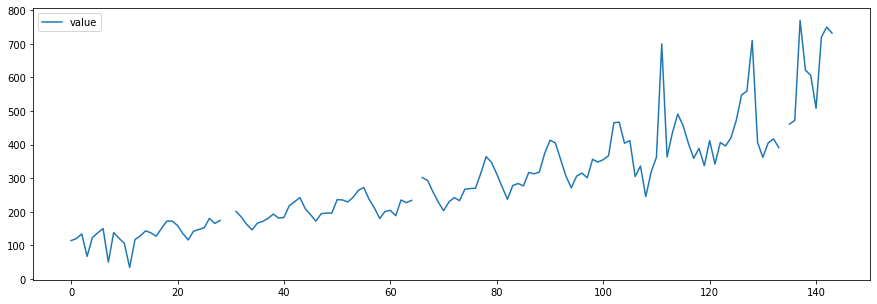

In [4]:
df.plot(figsize=(15,5))

### Interpolación lineal

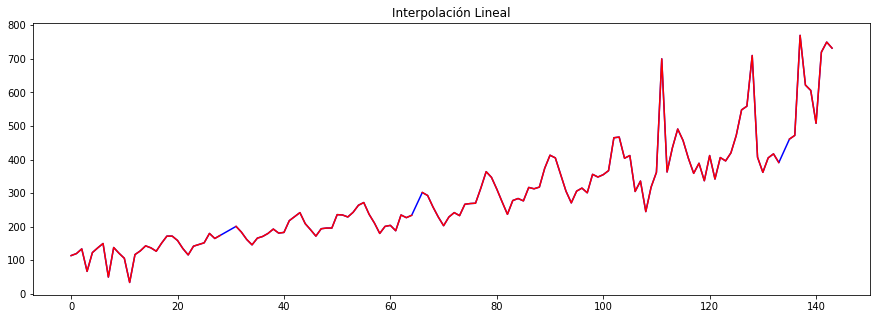

In [5]:
plt.rcParams['figure.figsize']=(15,5)
# on our data, impute the missing values using rolling window method
df['linear_int']= df['value'].interpolate(method='linear')
# plot the complete dataset
plt.plot(df['linear_int'], color='blue')
plt.plot(df['value'],color='red' )
# add the tittle of our plot as Linear interpolation
plt.title('Interpolación Lineal')
# print the plot
plt.show()

### Interpolación cúbica

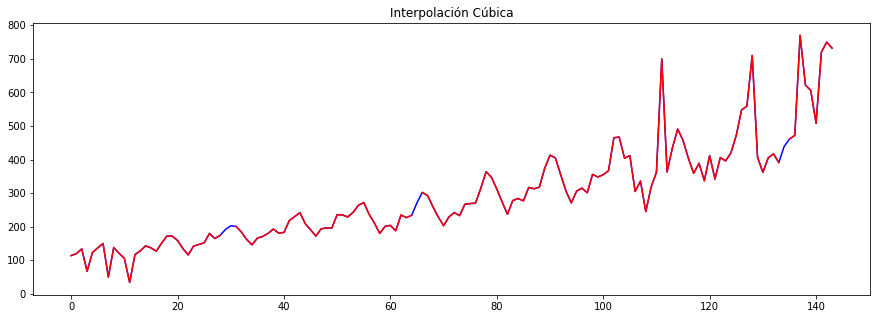

In [6]:
plt.rcParams['figure.figsize']=(15,5)
# on our data, impute the missing values using rolling window method
df['cubic_int']= df['value'].interpolate(method='cubic')
# plot the complete dataset
plt.plot(df['cubic_int'], color='b')
plt.plot(df['value'],color='red' )
# add the tittle of our plot as Linear interpolation
plt.title('Interpolación Cúbica')
# print the plot
plt.show()

### Last Observation Carried Forward (LOCF) 

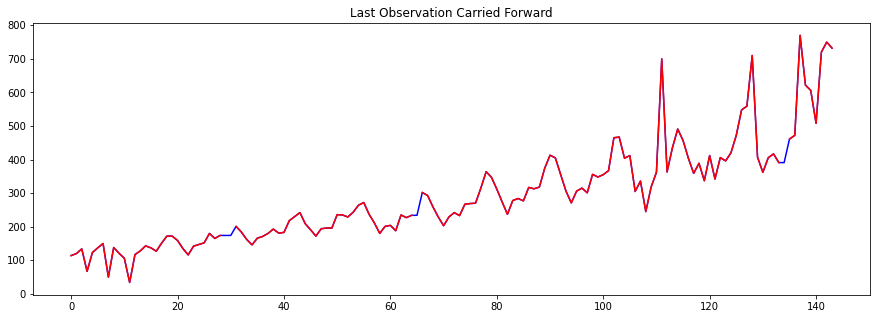

In [7]:
plt.rcParams['figure.figsize']=(15,5)
# On the customer column of our data, impute the missing values with the LOCF
df['LOCF']= df['value'].fillna(method ='ffill')
# plot our time series with imputed values
plt.plot(df['LOCF'], color='blue')
plt.plot(df['value'],color='red' )

#Plot tittle
plt.title('Last Observation Carried Forward')
# show the plot
plt.show()

### Next Observation Carried Backward (NOCB)

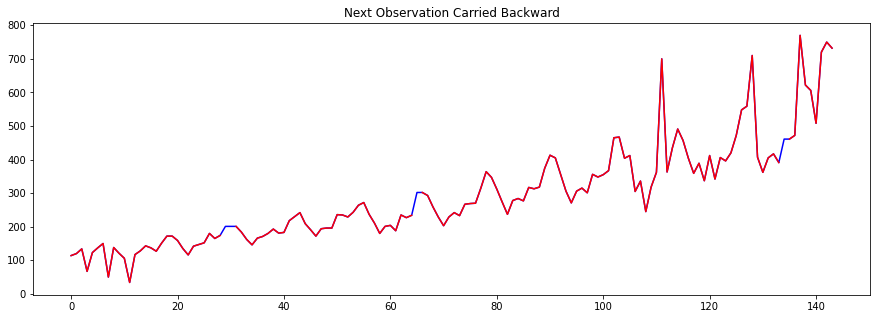

In [8]:
plt.rcParams['figure.figsize']=(15,5)
# On the customer column of our data, impute the missing values with the LOCF
df['NOCB']= df['value'].fillna(method ='bfill')
# plot our time series with imputed values
plt.plot(df['NOCB'], color='blue')
plt.plot(df['value'],color='red' )

#Plot tittle
plt.title('Next Observation Carried Backward')
# show the plot
plt.show()

<AxesSubplot:title={'center':'Next Observation Carried Backward'}>

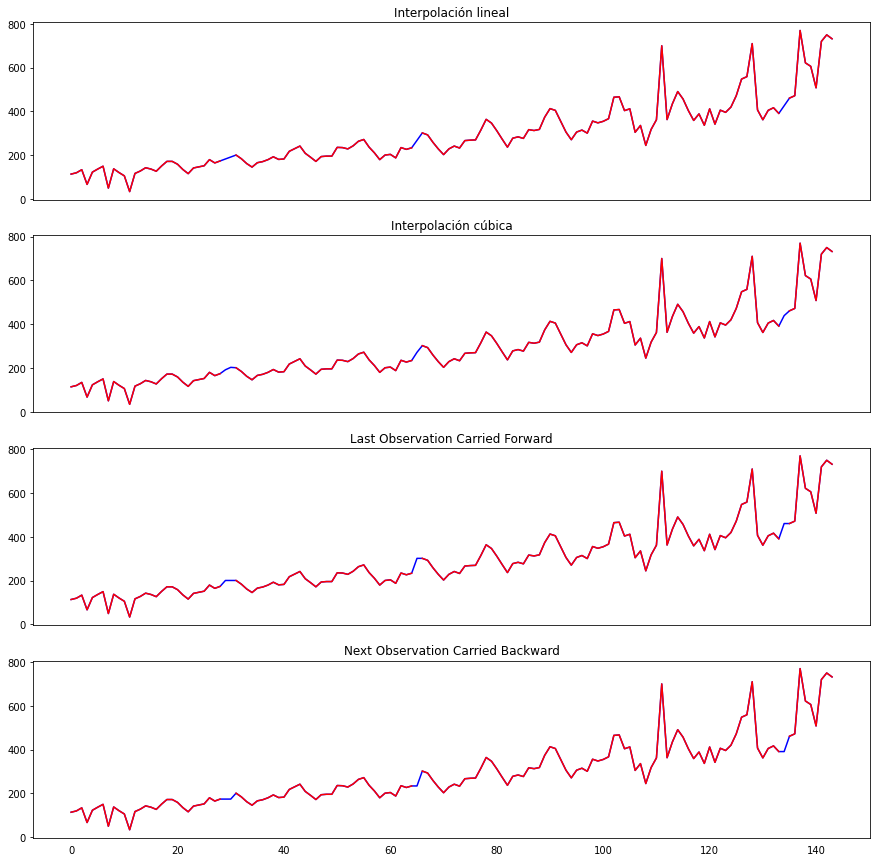

In [69]:
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(15, 15))
plt.rcParams.update({'xtick.bottom' : False})

df['linear_int'].plot(title="Interpolación lineal", ax=axes[0], label='Linear Int', color='blue')
df["value"].plot(ax=axes[0], label='Original', color='red')

df['cubic_int'].plot(title="Interpolación cúbica", ax=axes[1], label='Cubic Int', color='blue')
df["value"].plot(ax=axes[1], label='Original', color='red')

df['LOCF'].plot(title="Last Observation Carried Forward", ax=axes[2], label='LOCF', color='blue')
df["value"].plot(ax=axes[2], label='Original', color='red')

df['NOCB'].plot(title="Next Observation Carried Backward", ax=axes[3], label='NOCB', color='blue')
df["value"].plot(ax=axes[3], label='Original', color='red')
